# Univariate stochastic volatility: S&P 500
Research notebook by Jiayin Wang. See the repository README for data requirements and limitations.
Saved model outputs are retained from the supplied notebook. The included data-processing pipeline has been checked; the full estimation and MCMC workflow has not been rerun for this package.


In [ ]:
from pathlib import Path
import os
if (Path.cwd() / "notebooks").is_dir():
    os.chdir(Path.cwd() / "notebooks")
if not (Path.cwd().parent / "data" / "raw").is_dir():
    raise RuntimeError("Run this notebook from the repository root or notebooks directory.")
Path("../figures").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)


In [ ]:
#安装package
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



module 1：read and plot the data

In [3]:
file_path = "../data/raw/sp500_raw.xlsx"

raw = pd.read_excel(
    file_path,
    header=None,
    names=["date", "P_t"]
)

raw.head()

,date,P_t
0,2009-12-01,"1,110.38"
1,2009-11-01,"1,088.07"
2,2009-10-01,"1,067.66"
3,2009-09-01,"1,044.55"
4,2009-08-01,"1,009.73"


In [4]:
raw["P_t"] = (
    raw["P_t"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("\u2002", "", regex=False)
    .str.replace("\xa0", "", regex=False)
    .str.strip()
)

raw["P_t"] = pd.to_numeric(raw["P_t"], errors="coerce")
raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
raw = raw.dropna(subset=["date", "P_t"]).copy()
raw = raw.sort_values("date")
monthly = raw.set_index("date")
display(monthly.head())
display(monthly.tail())
print("Monthly observations:", len(monthly))
#必须重启kernel再跑，不然变量状态容易污染：set_index("date") = 把 date 从 column 移到 index

,P_t
date,
1962-01-01,69.07
1962-02-01,70.22
1962-03-01,70.29
1962-04-01,68.05
1962-05-01,62.99


,P_t
date,
2009-08-01,1009.73
2009-09-01,1044.55
2009-10-01,1067.66
2009-11-01,1088.07
2009-12-01,1110.38


Monthly observations: 576


In [5]:
monthly["log_P_t"] = np.log(monthly["P_t"])
monthly.head()
returns = pd.DataFrame(index=monthly.index)
returns["r_t"] = 100 * monthly["log_P_t"].diff()
returns = returns.dropna()

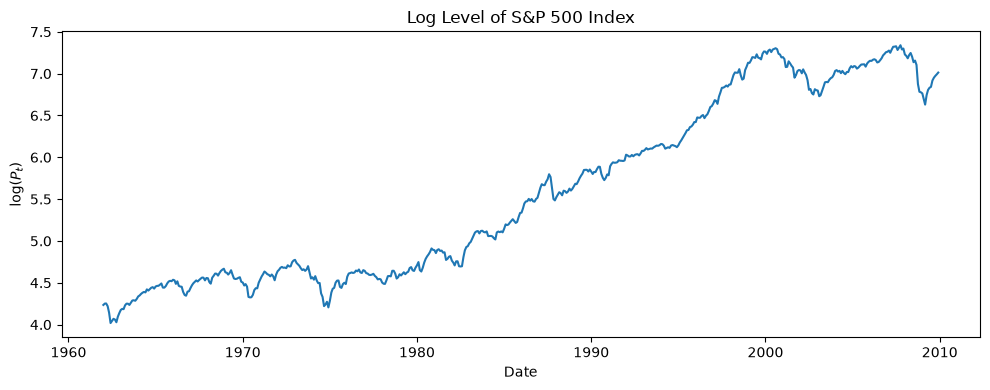

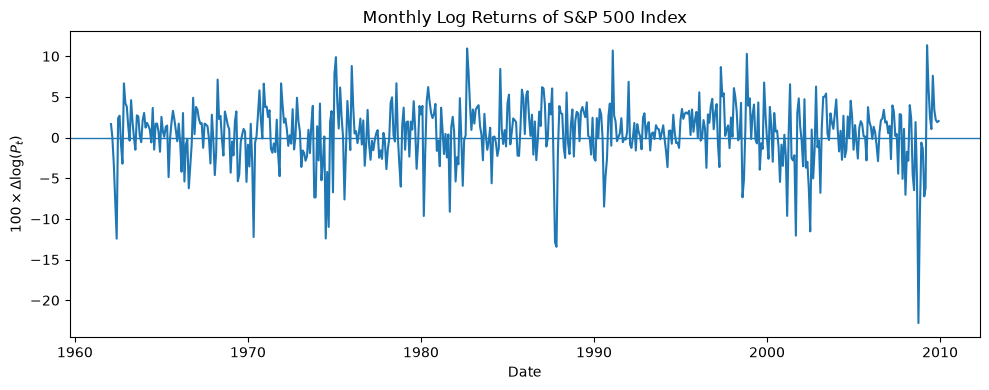

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly["log_P_t"])
plt.title("Log Level of S&P 500 Index")
plt.xlabel("Date")
plt.ylabel(r"$\log(P_t)$")
plt.tight_layout()
plt.savefig("../figures/fig_12_4a_log_index_level.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(returns.index, returns["r_t"])
plt.axhline(0, linewidth=1)
plt.title("Monthly Log Returns of S&P 500 Index")
plt.xlabel("Date")
plt.ylabel(r"$100 \times \Delta \log(P_t)$")
plt.tight_layout()
plt.savefig("../figures/fig_12_4b_log_returns.png", dpi=300)
plt.show()


观察：monthly log returns的极端点和课本不一致，影响了后面GARCHstandardized residuals
尝试了
1，使用simpe log return 但没有作用
2.计算均值放入miu，而非直接fit模型，均值为0.48，也没有用（python用的Gaussin likelihood）
3. 将数据替换成inflation adjusted但是发现更是完全不一样
猜测：数据源不同，课本是adjusted,但不是inflation adjusted
我的数据来源：https://www.multpl.com/s-p-500-historical-prices/table/by-month

核心原因：monthly average closing price
≠
closing index of the first trading day of each month
几个数据源的尝试：
Yahoo只到1985，federal到2016
multipl是average
macrotrends是inflation adjusted

综上选择了差别最小的multipl



Module 2: GARCH(1,1)

In [7]:
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox

In [8]:
#输入准备
r = returns["r_t"].copy()
assert np.all(np.isfinite(r)), "r_t contains invalid values"
assert len(r) == 575, f"Expected T = 575, but got T = {len(r)}"

In [9]:
# Fit Gaussian GARCH(1,1)


garch_model = arch_model(
    r,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)

garch_res = garch_model.fit(disp="off")

garch_params = garch_res.params

mu_garch = garch_params["mu"]
omega_garch = garch_params["omega"]
alpha_garch = garch_params["alpha[1]"]
beta_garch = garch_params["beta[1]"]

print(f"r_t = {mu_garch:.4f} + a_t")
print("a_t = sqrt(h_t) * epsilon_t,   epsilon_t ~ N(0, 1)")
print(
    f"h_t = {omega_garch:.4f} "
    f"+ {alpha_garch:.4f} * a_(t-1)^2 "
    f"+ {beta_garch:.4f} * h_(t-1)"
)



r_t = 0.7037 + a_t
a_t = sqrt(h_t) * epsilon_t,   epsilon_t ~ N(0, 1)
h_t = 1.0959 + 0.1819 * a_(t-1)^2 + 0.7527 * h_(t-1)


In [10]:
from statsmodels.stats.diagnostic import acorr_ljungbox
# Extract GARCH fitted objects
a_garch = garch_res.resid
sqrt_h_garch = garch_res.conditional_volatility
h_garch = sqrt_h_garch ** 2
eps_garch = garch_res.std_resid
# Ljung-Box tests for standardized residuals 和 squared standardized residuals
garch_output = pd.DataFrame({
    "r_t": r,
    "a_garch": a_garch,
    "sqrt_h_garch": sqrt_h_garch,
    "h_garch": h_garch,
    "eps_garch": eps_garch,
    "eps_garch_sq": eps_garch ** 2
})

lags = [12]

lb_eps_garch = acorr_ljungbox(
    garch_output["eps_garch"],
    lags=lags,
    return_df=True
)

lb_eps_garch_sq = acorr_ljungbox(
    garch_output["eps_garch_sq"],
    lags=lags,
    return_df=True
)

print("Ljung-Box statistics for GARCH standardized residuals:")
display(lb_eps_garch)

print("Ljung-Box statistics for squared GARCH standardized residuals:")
display(lb_eps_garch_sq)

Ljung-Box statistics for GARCH standardized residuals:


,lb_stat,lb_pvalue
12,34.05603,0.000661


Ljung-Box statistics for squared GARCH standardized residuals:


,lb_stat,lb_pvalue
12,8.725412,0.726188


我的standardized residuals有很明显的自相关，说明return series有明显不一致

Module 3：Prior and initla values

In [11]:
#将Module2的canonical variables转化为可输入MCMC的Numpy变量

r_array = r.to_numpy(dtype=np.float64)
dates = r.index
T = len(r_array)

h0_array = garch_output["h_garch"].to_numpy(dtype=np.float64)
z0 = np.log(h0_array)

assert T == 575
assert r_array.shape == (T,)
assert h0_array.shape == (T,)
assert z0.shape == (T,)

assert np.all(np.isfinite(r_array))
assert np.all(np.isfinite(h0_array))
assert np.all(h0_array > 0)
assert np.all(np.isfinite(z0))

print("T =", T)



T = 575


In [12]:
#初始值：用OLS得到omega(0),均值得到μ0（beta）
#μ0
mu_init = np.mean(r_array)
#omega0

# OLS regression:
# z_t = alpha0 + alpha1 * z_{t-1} + v_t

Y = z0[1:]
X = np.column_stack([
    np.ones(T - 1),
    z0[:-1]
])

alpha_init, _, _, _ = np.linalg.lstsq(X, Y, rcond=None)

alpha0_init = alpha_init[0]
alpha1_init = alpha_init[1]

resid_z = Y - X @ alpha_init

#下面这个就是方差而非标准差
sigma_v2_init = np.mean(resid_z ** 2)

print("Initial values for SV model:")
print("mu_init       =", mu_init)
print("alpha0_init   =", alpha0_init)
print("alpha1_init   =", alpha1_init)
print("sigma_v2_init =", sigma_v2_init)

Initial values for SV model:
mu_init       = 0.4830151469499256
alpha0_init   = 0.24778041271847356
alpha1_init   = 0.9007535142900523
sigma_v2_init = 0.05525355962147311


总结一下，到现在为止，MCMC进入前的输入变量如下
r_array
dates
T
h0_array
z0

mu_init
alpha0_init
alpha1_init
sigma_v2_init

Module 4：构建循环前的数组

In [13]:

# 1. MCMC settings

num_iter = 2500
burn_in = 500
grid_size = 400

rng = np.random.default_rng(seed=123)


# 2. Current states for Gibbs sampler
# These variables will be updated inside the Gibbs loop.

mu = float(mu_init)

h = h0_array.copy()
# h is the current variance path H = (h_1, ..., h_T)

alpha = np.array([alpha0_init, alpha1_init], dtype=np.float64)
# alpha[0] = alpha0
# alpha[1] = alpha1

sigma_v2 = float(sigma_v2_init)


# 3. Storage arrays for MCMC samples

mu_samples = np.empty(num_iter, dtype=np.float64)

h_samples = np.empty((num_iter, T), dtype=np.float64)

alpha_samples = np.empty((num_iter, 2), dtype=np.float64)
# alpha_samples[:, 0] stores alpha0 samples
# alpha_samples[:, 1] stores alpha1 samples

sigma_v2_samples = np.empty(num_iter, dtype=np.float64)


# 4. Sanity checks

assert isinstance(num_iter, int)
assert isinstance(burn_in, int)
assert isinstance(grid_size, int)

assert num_iter > burn_in
assert grid_size > 0

assert r_array.shape == (T,)
assert h0_array.shape == (T,)
assert h.shape == (T,)
assert z0.shape == (T,)

assert alpha.shape == (2,)

assert np.all(np.isfinite(r_array))
assert np.all(np.isfinite(h0_array))
assert np.all(h0_array > 0)
assert np.all(np.isfinite(z0))

assert np.isfinite(mu)
assert np.all(np.isfinite(h))
assert np.all(h > 0)

assert np.all(np.isfinite(alpha))
assert np.isfinite(sigma_v2)
assert sigma_v2 > 0


# 5. Print current setup

print("MCMC arrays and current states prepared.")
print("----------------------------------------")
print("num_iter   =", num_iter)
print("burn_in    =", burn_in)
print("grid_size  =", grid_size)
print("T          =", T)
print()
print("Current states:")
print("mu         =", mu)
print("alpha0     =", alpha[0])
print("alpha1     =", alpha[1])
print("sigma_v2   =", sigma_v2)
print()
print("Storage shapes:")
print("mu_samples.shape       =", mu_samples.shape)
print("h_samples.shape        =", h_samples.shape)
print("alpha_samples.shape    =", alpha_samples.shape)
print("sigma_v2_samples.shape =", sigma_v2_samples.shape)

MCMC arrays and current states prepared.
----------------------------------------
num_iter   = 2500
burn_in    = 500
grid_size  = 400
T          = 575

Current states:
mu         = 0.4830151469499256
alpha0     = 0.24778041271847356
alpha1     = 0.9007535142900523
sigma_v2   = 0.05525355962147311

Storage shapes:
mu_samples.shape       = (2500,)
h_samples.shape        = (2500, 575)
alpha_samples.shape    = (2500, 2)
sigma_v2_samples.shape = (2500,)


Module 5:Gribbs functions definitions
Blocks:
  1. sample mu
  2. sample H by Griddy Gibbs
  3. sample Omega = (alpha0, alpha1, sigma_v2)
对1， 定义函数def sample_mu(r_array, h, rng)
对2， 定义函数 log_conditional_h_grid 和 sample_h_griddy
对3， 定义函数 sample_h_griddy和sample_h_griddy

In [14]:
# ==================================================
# Gibbs Sampler for Univariate Stochastic Volatility
# Blocks:
#   1. sample mu
#   2. sample H by Griddy Gibbs
#   3. sample Omega = (alpha0, alpha1, sigma_v2)
# ==================================================


# --------------------------------------------------
# Block 1: Sample mu | r, H
# --------------------------------------------------

def sample_mu(r_array, h, rng):
    """
    Sample mu from p(mu | r, H).

    Model:
        r_t | mu, h_t ~ N(mu, h_t)

    Prior:
        mu ~ N(0, 4)

    Posterior:
        Vn = (V0^{-1} + sum_t 1 / h_t)^{-1}

        mu_star = Vn * (V0^{-1} * mu0 + sum_t r_t / h_t)

        mu | r, H ~ N(mu_star, Vn)
    """

    mu0 = 0.0
    V0 = 4.0

    Vn = 1.0 / (1.0 / V0 + np.sum(1.0 / h))

    mu_star = Vn * (
        (1.0 / V0) * mu0
        + np.sum(r_array / h)
    )
#用random number generator,在正态分布中抽出一个数，保留随机性，而非直接输出mean
    mu_new = rng.normal(
        loc=mu_star,
        scale=np.sqrt(Vn)
    )

    return float(mu_new)

In [15]:
# --------------------------------------------------
# Block 2A: Log conditional density of h_t on grid
# --------------------------------------------------

def log_conditional_h_grid(
    h_grid,
    t,
    r_array,
    mu,
    h_current,
    alpha,
    sigma_v2
):
    """
    Compute log conditional density of h_t on a grid.

    Inputs:
        h_grid: candidate values of h_t, shape (grid_size,)
        t: current time index, Python 0-based
        r_array: return series
        mu: current mu
        h_current: current volatility path
        alpha: current alpha = (alpha0, alpha1)
        sigma_v2: current sigma_v^2

    Boundary cases:
        t = 0:
            observation density + Jacobian + forward transition

        0 < t < T - 1:
            observation density + Jacobian
            + backward transition + forward transition

        t = T - 1:
            observation density + Jacobian + backward transition
    """

    alpha0 = alpha[0]
    alpha1 = alpha[1]

    T = len(h_current)

    # Candidate z_t values
    z_grid = np.log(h_grid)

    # --------------------------------------------------
    # Observation equation:
    #
    # r_t | mu, h_t ~ N(mu, h_t)
    #
    # log p(r_t | mu, h_t)
    # ∝ -0.5 log(h_t) - (r_t - mu)^2 / (2h_t)
    # --------------------------------------------------

    obs_part = (
        -0.5 * np.log(h_grid)
        - (r_array[t] - mu) ** 2 / (2.0 * h_grid)
    )

    # --------------------------------------------------
    # Jacobian term:
    #
    # z_t = log(h_t)
    # dz_t / dh_t = 1 / h_t
    #
    # log Jacobian = -log(h_t)
    # --------------------------------------------------

    jacobian_part = -np.log(h_grid)

    log_density = obs_part + jacobian_part

    # At this point:
    #
    # obs_part + jacobian_part
    # =
    # -1.5 log(h_t) - (r_t - mu)^2 / (2h_t)

    # --------------------------------------------------
    # Backward transition:
    #
    # z_t | z_{t-1}
    # ~ N(alpha0 + alpha1 z_{t-1}, sigma_v2)
    #
    # only exists when t > 0
    # --------------------------------------------------

    if t > 0:
        z_left = np.log(h_current[t - 1])

        mean_backward = alpha0 + alpha1 * z_left

        backward_part = (
            - (z_grid - mean_backward) ** 2
            / (2.0 * sigma_v2)
        )

        log_density += backward_part

    # --------------------------------------------------
    # Forward transition:
    #
    # z_{t+1} | z_t
    # ~ N(alpha0 + alpha1 z_t, sigma_v2)
    #
    # only exists when t < T - 1
    # --------------------------------------------------

    if t < T - 1:
        z_right = np.log(h_current[t + 1])

        mean_forward = alpha0 + alpha1 * z_grid

        forward_part = (
            - (z_right - mean_forward) ** 2
            / (2.0 * sigma_v2)
        )

        log_density += forward_part

    return log_density

在这里使用log density的理由是更好地表达微小区分（grid之间的value差距可能很小）

In [16]:
# --------------------------------------------------
# Block 2B: Sample H | r, mu, alpha, sigma_v2
# by Griddy Gibbs
# --------------------------------------------------

def sample_h_griddy(
    r_array,
    mu,
    h_current,
    h0_array,
    alpha,
    sigma_v2,
    grid_size,
    rng
):
    """
    Sample the full volatility path H = (h_1, ..., h_T)
    using single-site Griddy Gibbs.

    For each t:
        1. Build grid for h_t
        2. Compute log conditional density on grid
        3. Stabilize log density
        4. Convert to probabilities
        5. Build CDF
        6. Draw u ~ Uniform(0, 1)
        7. Choose h_t using np.searchsorted
    """

    T = len(h_current)

    # Sequential updating path
    h_new = h_current.copy()

    for t in range(T):

        h_prev_t = h_current[t]
        h0_t = h0_array[t]

        # --------------------------------------------------
        # Grid range
        # eta1 = 0.6 * max(h_prev_t, h0_t)
        # eta2 = 1.4 * min(h_prev_t, h0_t)
        
        # But this may produce eta1 > eta2.
        

        eta1_t = 0.6 * max(h_prev_t, h0_t)
        eta2_t = 1.4 * min(h_prev_t, h0_t)

        # Numerical protection
        eta1_t = max(eta1_t, 1e-12)
        eta2_t = max(eta2_t, eta1_t * 1.0001)

        h_grid = np.linspace(
            eta1_t,
            eta2_t,
            grid_size
        )

        # --------------------------------------------------
        # Compute log conditional density
        # --------------------------------------------------

        log_density = log_conditional_h_grid(
            h_grid=h_grid,
            t=t,
            r_array=r_array,
            mu=mu,
            h_current=h_new,
            alpha=alpha,
            sigma_v2=sigma_v2
        )

        # --------------------------------------------------
        # Stabilize before exponentiation
        # --------------------------------------------------

        log_density = log_density - np.max(log_density)

        density = np.exp(log_density)

        density_sum = np.sum(density)

        # If numerical issue happens, keep old h_t
        if (not np.isfinite(density_sum)) or density_sum <= 0:
            h_new[t] = h_current[t]
            continue

        probs = density / density_sum

        cdf = np.cumsum(probs)

        # Force the final CDF value to be exactly 1
        cdf[-1] = 1.0

        # --------------------------------------------------
        # Inverse-CDF sampling
        # --------------------------------------------------

        u = rng.uniform()

        k = np.searchsorted(cdf, u)

        h_new[t] = h_grid[k]

    return h_new

In [17]:
# --------------------------------------------------
# Block 3A: Sample alpha | H, sigma_v2
# --------------------------------------------------

def sample_alpha(z, sigma_v2, rng):
    """
    Sample alpha = (alpha0, alpha1)' from p(alpha | H, sigma_v2).

    State equation:
        z_t = alpha0 + alpha1 z_{t-1} + v_t

    where:
        z_t = log(h_t)

    Prior:
        alpha ~ N(alpha_prior_mean, alpha_prior_cov)

        alpha_prior_mean = (0, 0.6)'
        alpha_prior_cov = diag(0.25, 0.04)
    """

    Y = z[1:]

    X = np.column_stack([
        np.ones(len(z) - 1),
        z[:-1]
    ])

    alpha_prior_mean = np.array([0.0, 0.6])
    alpha_prior_cov = np.diag([0.25, 0.04])

    alpha_prior_precision = np.linalg.inv(alpha_prior_cov)

    posterior_precision = (
        X.T @ X / sigma_v2
        + alpha_prior_precision
    )

    posterior_cov = np.linalg.inv(posterior_precision)

    posterior_mean = posterior_cov @ (
        X.T @ Y / sigma_v2
        + alpha_prior_precision @ alpha_prior_mean
    )

    alpha_new = rng.multivariate_normal(
        mean=posterior_mean,
        cov=posterior_cov
    )

    return alpha_new

In [18]:
# --------------------------------------------------
# Block 3B: Sample sigma_v2 | H, alpha
# --------------------------------------------------

def sample_sigma_v2(z, alpha, rng):
    """
    Sample sigma_v2 from p(sigma_v2 | H, alpha).

    State equation:
        z_t = alpha0 + alpha1 z_{t-1} + v_t

    Prior:
        10 * 0.1 / sigma_v2 ~ chi-square_10

    Posterior:
        sigma_v2 = (nu0 * s0_sq + SSE) / chi-square(nu0 + T - 1)
    """

    Y = z[1:]

    X = np.column_stack([
        np.ones(len(z) - 1),
        z[:-1]
    ])

    fitted = X @ alpha

    resid = Y - fitted

    sse = np.sum(resid ** 2)

    nu0 = 10.0
    s0_sq = 0.1

    n = len(Y)

    nu_star = nu0 + n
    scale_star = nu0 * s0_sq + sse

    chi2_draw = rng.chisquare(df=nu_star)

    sigma_v2_new = scale_star / chi2_draw

    return float(sigma_v2_new)

Module 6 full loop in operation and sanity check

In [19]:
# --------------------------------------------------
# Main Gibbs sampler
# --------------------------------------------------

for j in range(num_iter):

    # ==================================================
    # Block 1: sample mu | r, H
    # ==================================================

    mu = sample_mu(
        r_array=r_array,
        h=h,
        rng=rng
    )

    # ==================================================
    # Block 2: sample H | r, mu, alpha, sigma_v2
    # ==================================================

    h = sample_h_griddy(
        r_array=r_array,
        mu=mu,
        h_current=h,
        h0_array=h0_array,
        alpha=alpha,
        sigma_v2=sigma_v2,
        grid_size=grid_size,
        rng=rng
    )

    # ==================================================
    # Block 3: sample Omega = (alpha0, alpha1, sigma_v2)
    # ==================================================

    z = np.log(h)

    alpha = sample_alpha(
        z=z,
        sigma_v2=sigma_v2,
        rng=rng
    )

    sigma_v2 = sample_sigma_v2(
        z=z,
        alpha=alpha,
        rng=rng
    )

    # ==================================================
    # Store samples
    # ==================================================

    mu_samples[j] = mu

    h_samples[j, :] = h

    alpha_samples[j, :] = alpha

    sigma_v2_samples[j] = sigma_v2

    # ==================================================
    # Optional progress print
    # ==================================================

    if (j + 1) % 500 == 0:
        print(f"Iteration {j + 1} / {num_iter} completed.")
        print(
            "mu =",
            mu,
            "| alpha0 =",
            alpha[0],
            "| alpha1 =",
            alpha[1],
            "| sigma_v2 =",
            sigma_v2
        )

Iteration 500 / 2500 completed.
mu = 0.48679747370884485 | alpha0 = 0.1346543468125717 | alpha1 = 0.9406312483658802 | sigma_v2 = 0.029368644746261115
Iteration 1000 / 2500 completed.
mu = 0.6637499764813966 | alpha0 = 0.2157837334619871 | alpha1 = 0.9093942211830083 | sigma_v2 = 0.03152554337512415
Iteration 1500 / 2500 completed.
mu = 0.4477506364191769 | alpha0 = 0.19205059723155257 | alpha1 = 0.9273472575253776 | sigma_v2 = 0.03840908298886483
Iteration 2000 / 2500 completed.
mu = 0.8562708723874111 | alpha0 = 0.15142152331109884 | alpha1 = 0.937683907971695 | sigma_v2 = 0.028406753041770816
Iteration 2500 / 2500 completed.
mu = 0.5086836070533315 | alpha0 = 0.12439296566966951 | alpha1 = 0.9463396855054053 | sigma_v2 = 0.029790669937441887


In [20]:
# --------------------------------------------------
# Posterior samples after burn-in
# --------------------------------------------------

post_mu = mu_samples[burn_in:]

post_h = h_samples[burn_in:, :]

post_alpha = alpha_samples[burn_in:, :]

post_alpha0 = post_alpha[:, 0]
post_alpha1 = post_alpha[:, 1]

post_sigma_v2 = sigma_v2_samples[burn_in:]


# Posterior mean of volatility path
h_mean = np.mean(post_h, axis=0)


print("Posterior samples prepared.")
print("---------------------------")
print("post_mu.shape       =", post_mu.shape)
print("post_h.shape        =", post_h.shape)
print("post_alpha.shape    =", post_alpha.shape)
print("post_alpha0.shape   =", post_alpha0.shape)
print("post_alpha1.shape   =", post_alpha1.shape)
print("post_sigma_v2.shape =", post_sigma_v2.shape)
print("h_mean.shape        =", h_mean.shape)

Posterior samples prepared.
---------------------------
post_mu.shape       = (2000,)
post_h.shape        = (2000, 575)
post_alpha.shape    = (2000, 2)
post_alpha0.shape   = (2000,)
post_alpha1.shape   = (2000,)
post_sigma_v2.shape = (2000,)
h_mean.shape        = (575,)


In [21]:
# --------------------------------------------------
# Sanity checks after MCMC
# --------------------------------------------------

assert np.all(np.isfinite(mu_samples))

assert np.all(np.isfinite(h_samples))
assert np.all(h_samples > 0)

assert np.all(np.isfinite(alpha_samples))

assert np.all(np.isfinite(sigma_v2_samples))
assert np.all(sigma_v2_samples > 0)

assert post_h.shape == (num_iter - burn_in, T)
assert h_mean.shape == (T,)

print("MCMC completed successfully.")

MCMC completed successfully.


Module 7 statistics summary

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, invgamma, gaussian_kde

os.makedirs("figures", exist_ok=True)

In [23]:
# --------------------------------------------------
# Posterior summary table
# --------------------------------------------------

posterior_summary = pd.DataFrame({
    "Parameter": ["mu", "alpha0", "alpha1", "sigma_v2"],
    "Posterior mean": [
        np.mean(post_mu),
        np.mean(post_alpha0),
        np.mean(post_alpha1),
        np.mean(post_sigma_v2)
    ],
    "Posterior std": [
        np.std(post_mu, ddof=1),
        np.std(post_alpha0, ddof=1),
        np.std(post_alpha1, ddof=1),
        np.std(post_sigma_v2, ddof=1)
    ],
    "Textbook mean": [
        0.409,
        0.454,
        0.837,
        0.086
    ],
    "Textbook std": [
        0.157,
        0.068,
        0.025,
        0.007
    ]
})

posterior_summary["Mean difference"] = (
    posterior_summary["Posterior mean"]
    - posterior_summary["Textbook mean"]
)

posterior_summary["Std difference"] = (
    posterior_summary["Posterior std"]
    - posterior_summary["Textbook std"]
)

posterior_summary

,Parameter,Posterior mean,Posterior std,Textbook mean,Textbook std,Mean difference,Std difference
0,mu,0.575008,0.130912,0.409,0.157,0.166008,-0.026088
1,alpha0,0.136482,0.036340,0.454,0.068,-0.317518,-0.031660
2,alpha1,0.942397,0.014967,0.837,0.025,0.105397,-0.010033
3,sigma_v2,0.032096,0.002884,0.086,0.007,-0.053904,-0.004116


数据评价：我的数据结果更平滑，在不调整grid的定义的条件下，可能就是数据源来自average，导致更加平均，相邻两项之间关联更大，随机项的波动更小引起的

In [24]:
# --------------------------------------------------
# Prior density helper functions
# --------------------------------------------------

def prior_mu_pdf(x):
    return norm.pdf(x, loc=0.0, scale=np.sqrt(4.0))


def prior_alpha0_pdf(x):
    return norm.pdf(x, loc=0.0, scale=np.sqrt(0.25))


def prior_alpha1_pdf(x):
    return norm.pdf(x, loc=0.6, scale=np.sqrt(0.04))


def prior_sigma_v2_pdf(x):
    nu0 = 10.0
    s0_sq = 0.1

    shape = nu0 / 2.0
    scale = nu0 * s0_sq / 2.0

    return invgamma.pdf(x, a=shape, scale=scale)

In [28]:
# --------------------------------------------------
# Helper function: plot prior and posterior density
# --------------------------------------------------

def plot_prior_posterior_density(
    posterior_samples,
    prior_pdf,
    parameter_name,
    filename,
    positive_support=False
):
    """
    Plot prior density and posterior density for one parameter.

    Dashed line: prior density
    Solid line: posterior density
    """

    posterior_samples = np.asarray(posterior_samples)

    assert posterior_samples.ndim == 1
    assert np.all(np.isfinite(posterior_samples))

    if positive_support:
        lower = max(1e-8, np.percentile(posterior_samples, 0.5) * 0.5)
    else:
        lower = np.percentile(posterior_samples, 0.5)

    upper = np.percentile(posterior_samples, 99.5)

    # Expand plotting range slightly
    width = upper - lower
    x_min = lower - 0.3 * width
    x_max = upper + 0.3 * width

    if positive_support:
        x_min = max(1e-8, x_min)

    x_grid = np.linspace(x_min, x_max, 500)

    posterior_kde = gaussian_kde(posterior_samples)
    posterior_density = posterior_kde(x_grid)

    prior_density = prior_pdf(x_grid)

    plt.figure(figsize=(7, 4))

    plt.plot(
        x_grid,
        prior_density,
        linestyle="--",
        label="Prior density"
    )

    plt.plot(
        x_grid,
        posterior_density,
        linestyle="-",
        label="Posterior density"
    )

    plt.title(f"Prior and Posterior Density of {parameter_name}")
    plt.xlabel(parameter_name)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()

    plt.savefig(filename, dpi=300)
    plt.show()

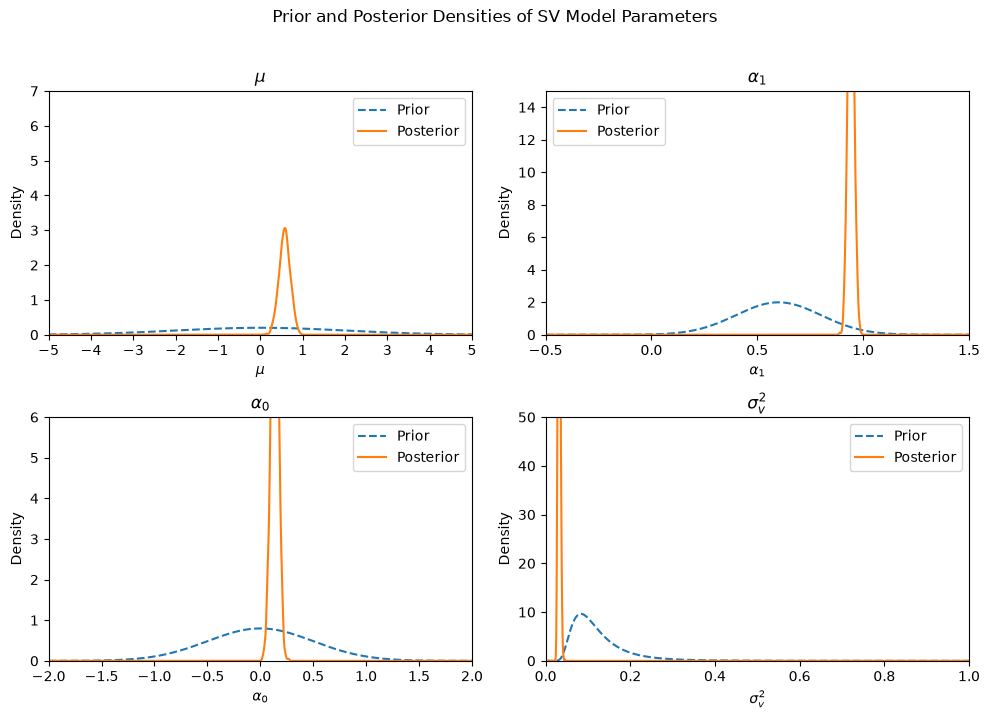

In [31]:
# --------------------------------------------------
# Combined 2x2 density plot with fixed axis scales
# --------------------------------------------------

density_plot_specs = [
    {
        "samples": post_mu,
        "prior_pdf": prior_mu_pdf,
        "name": r"$\mu$",
        "xlim": (-5.0, 5.0),
        "ylim": (0.0, 7.0),
        "xticks": np.arange(-5.0, 5.1, 1.0)
    },
     {
        "samples": post_alpha1,
        "prior_pdf": prior_alpha1_pdf,
        "name": r"$\alpha_1$",
        "xlim": (-0.5, 1.5),
        "ylim": (0.0, 15.0),
        "xticks": np.arange(-0.5, 1.6, 0.5)
    },
    {
        "samples": post_alpha0,
        "prior_pdf": prior_alpha0_pdf,
        "name": r"$\alpha_0$",
        "xlim": (-2.0, 2.0),
        "ylim": (0.0, 6.0),
        "xticks": np.arange(-2.0, 2.1, 0.5)
    },
    {
        "samples": post_sigma_v2,
        "prior_pdf": prior_sigma_v2_pdf,
        "name": r"$\sigma_v^2$",
        "xlim": (0.0, 1.0),
        "ylim": (0.0, 50.0),
        "xticks": np.arange(0.0, 1.01, 0.2)
    }
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes = axes.ravel()

for ax, spec in zip(axes, density_plot_specs):

    samples = np.asarray(spec["samples"])

    assert samples.ndim == 1
    assert np.all(np.isfinite(samples))

    x_min, x_max = spec["xlim"]

    x_grid = np.linspace(x_min, x_max, 1000)

    posterior_kde = gaussian_kde(samples)

    prior_density = spec["prior_pdf"](x_grid)
    posterior_density = posterior_kde(x_grid)

    ax.plot(
        x_grid,
        prior_density,
        linestyle="--",
        label="Prior"
    )

    ax.plot(
        x_grid,
        posterior_density,
        linestyle="-",
        label="Posterior"
    )

    ax.set_title(spec["name"])
    ax.set_xlabel(spec["name"])
    ax.set_ylabel("Density")

    ax.set_xlim(spec["xlim"])
    ax.set_ylim(spec["ylim"])
    ax.set_xticks(spec["xticks"])

    ax.legend()

plt.suptitle(
    "Prior and Posterior Densities of SV Model Parameters",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "figures/fig_12_5_prior_posterior_densities_combined_fixed_scale.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [25]:
# --------------------------------------------------
# Helper function: plot prior and posterior density
# --------------------------------------------------

def plot_prior_posterior_density(
    posterior_samples,
    prior_pdf,
    parameter_name,
    filename,
    positive_support=False
):
    """
    Plot prior density and posterior density for one parameter.

    Dashed line: prior density
    Solid line: posterior density
    """

    posterior_samples = np.asarray(posterior_samples)

    assert posterior_samples.ndim == 1
    assert np.all(np.isfinite(posterior_samples))

    if positive_support:
        lower = max(1e-8, np.percentile(posterior_samples, 0.5) * 0.5)
    else:
        lower = np.percentile(posterior_samples, 0.5)

    upper = np.percentile(posterior_samples, 99.5)

    # Expand plotting range slightly
    width = upper - lower
    x_min = lower - 0.3 * width
    x_max = upper + 0.3 * width

    if positive_support:
        x_min = max(1e-8, x_min)

    x_grid = np.linspace(x_min, x_max, 500)

    posterior_kde = gaussian_kde(posterior_samples)
    posterior_density = posterior_kde(x_grid)

    prior_density = prior_pdf(x_grid)

    plt.figure(figsize=(7, 4))

    plt.plot(
        x_grid,
        prior_density,
        linestyle="--",
        label="Prior density"
    )

    plt.plot(
        x_grid,
        posterior_density,
        linestyle="-",
        label="Posterior density"
    )

    plt.title(f"Prior and Posterior Density of {parameter_name}")
    plt.xlabel(parameter_name)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()

    plt.savefig(filename, dpi=300)
    plt.show()

In [26]:
# --------------------------------------------------
# Build time index for plots
# --------------------------------------------------
# 如果你前面有 returns DataFrame，并且 index 是日期，可以用它。
# 例如 returns.index 是 monthly dates。

if "returns" in globals():
    try:
        time_index = returns.index
    except Exception:
        time_index = np.arange(T)
else:
    time_index = np.arange(T)


assert len(time_index) == T
assert h0_array.shape == (T,)
assert h_mean.shape == (T,)

assert np.all(np.isfinite(h0_array))
assert np.all(h0_array > 0)

assert np.all(np.isfinite(h_mean))
assert np.all(h_mean > 0)

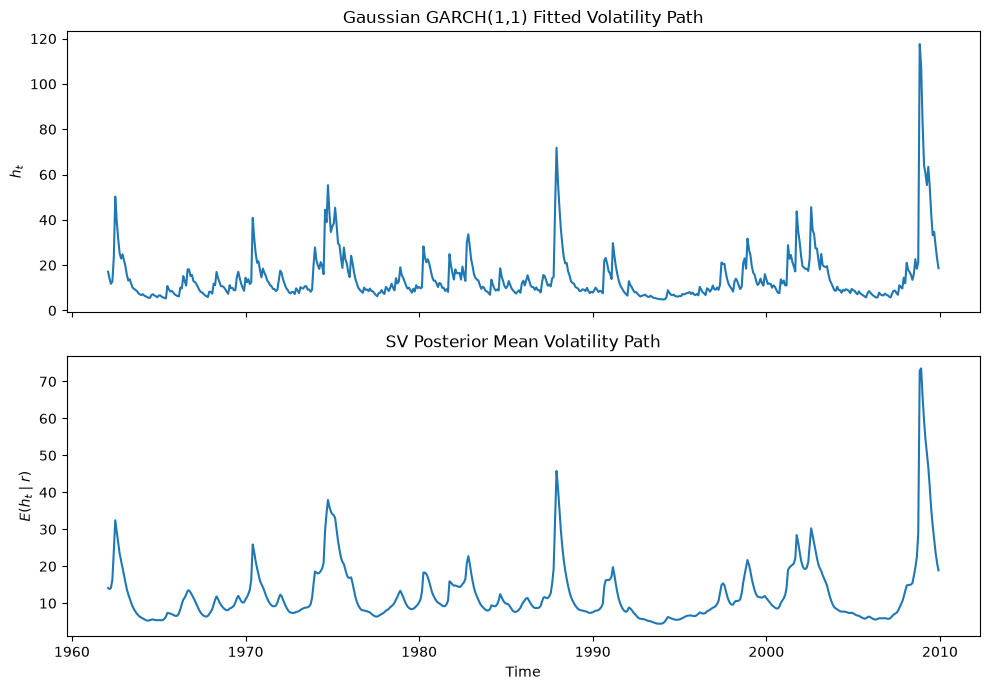

In [27]:
# --------------------------------------------------
# Figure: Time plots of fitted volatilities
# --------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(time_index, h0_array)
axes[0].set_title("Gaussian GARCH(1,1) Fitted Volatility Path")
axes[0].set_ylabel(r"$h_t$")

axes[1].plot(time_index, h_mean)
axes[1].set_title("SV Posterior Mean Volatility Path")
axes[1].set_xlabel("Time")
axes[1].set_ylabel(r"$E(h_t \mid r)$")

plt.tight_layout()

plt.savefig(
    "figures/fig_12_6_garch_vs_sv_volatility.png",
    dpi=300
)

plt.show()